Using device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 492kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.50MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.06MB/s]



--- Dataset Description ---
Training images : 60000
Test images     : 10000
Total images    : 70000
Image size      : (1, 28, 28) (1 channel, 28x28)
Features/image  : 784 (when flattened)
Target classes  : 10 (digits 0-9)

Train: 48000 | Validation: 12000 | Test: 10000


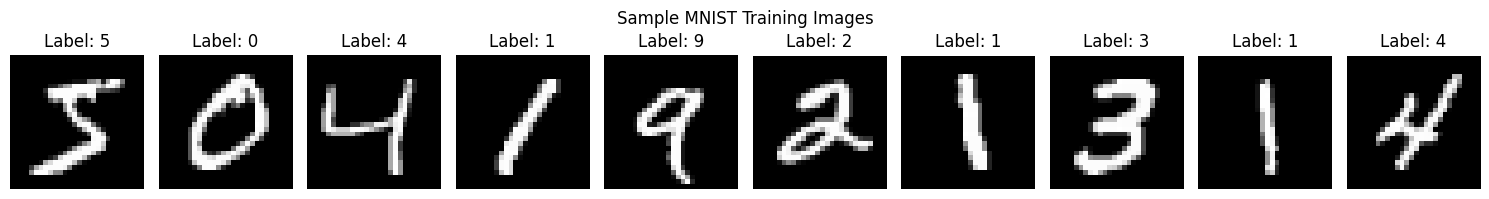


--- Model Architecture ---
MultilayerFeedForwardNet(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): ReLU()
    (6): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): ReLU()
    (10): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=128, out_features=10, bias=True)
  )
)
Total trainable parameters: 569,226

--- Training ---
Epoch [01/10] Train Loss: 0.3048 | Train Acc: 90.83% | Val Loss: 0.2063 | Val Acc: 93.40%
Epoch [02/10] Train Loss: 0.1854 | Train Acc: 94.25% | Val Loss: 0.1231 | Val Acc: 96.

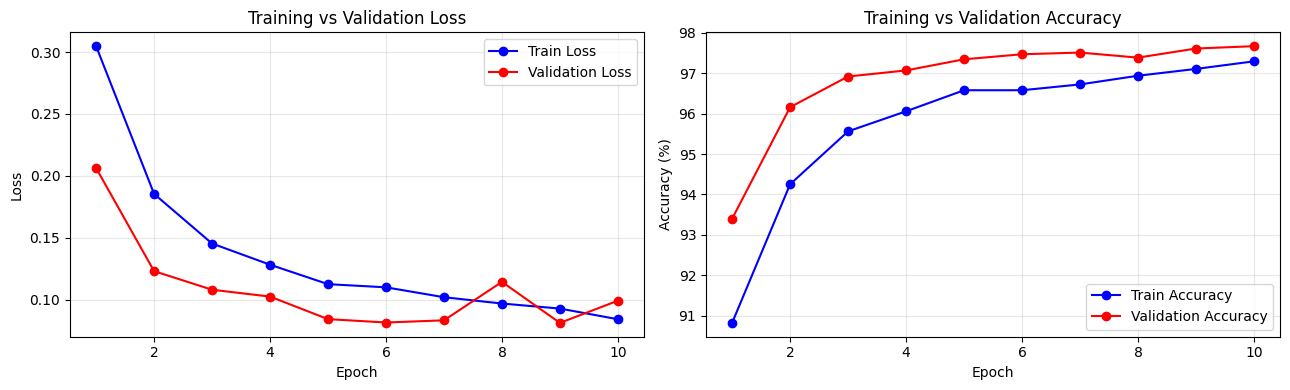


--- Test Results ---
Test Loss     : 0.0703
Test Accuracy : 97.84%

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.99      0.97      0.98      1010
           4       0.98      0.97      0.98       982
           5       0.99      0.98      0.98       892
           6       0.98      0.98      0.98       958
           7       0.98      0.96      0.97      1028
           8       0.98      0.98      0.98       974
           9       0.95      0.98      0.96      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



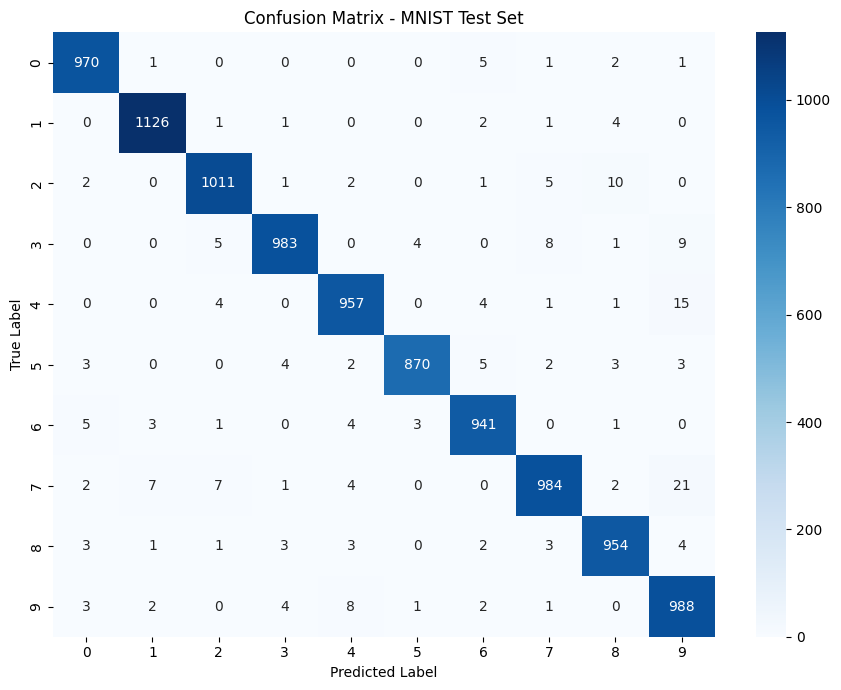

Most often misclassified digit: 7 (44 errors)


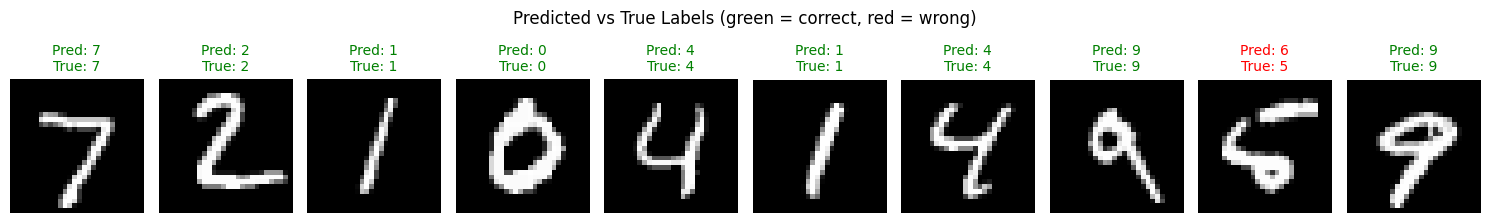

Model saved as 'mnist_classifier.pth'

--- MLP Accuracy Results (1 to 9 hidden layers, 64 units each) ---
Hidden layers: 1   Accuracy: 96.64%
Hidden layers: 2   Accuracy: 96.31%
Hidden layers: 3   Accuracy: 96.17%
Hidden layers: 4   Accuracy: 95.93%
Hidden layers: 5   Accuracy: 95.27%
Hidden layers: 6   Accuracy: 95.11%
Hidden layers: 7   Accuracy: 94.90%
Hidden layers: 8   Accuracy: 93.87%
Hidden layers: 9   Accuracy: 93.98%

Best Number of Hidden Layers : 1
Best Accuracy                : 96.64%
Best Architecture            : (64,)


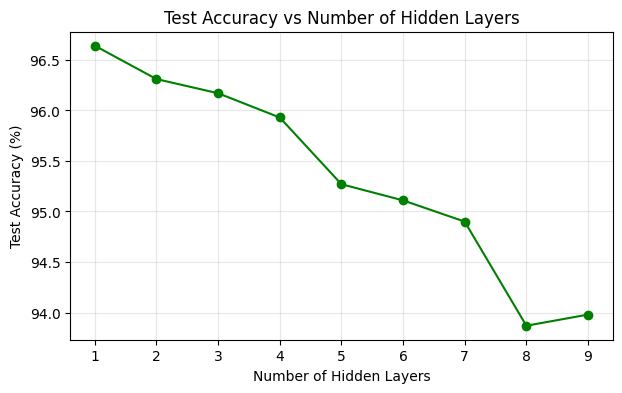

In [ ]:
"""
AI-Based Handwritten Digit Recognition using a Multilayer Feed-Forward
Deep Neural Network on the MNIST Dataset  (PyTorch)

Task steps covered
  1. Data Loading        -> torchvision.datasets.MNIST
  2. Data Preprocessing  -> ToTensor + Normalize(0.1307, 0.3081)
  3. Model Building      -> Multilayer feed-forward network (fully connected)
  4. Model Training      -> Adam + CrossEntropyLoss, train/validation tracking
  5. Model Evaluation    -> test loss/accuracy, classification report, confusion matrix
  6. Visualization       -> training curves, confusion matrix, sample predictions

Run in Google Colab (Runtime > Change runtime type > T4 GPU) as a single cell.
"""

# ----------------------------------------------------------------------
# S1: SETUP
# ----------------------------------------------------------------------
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Set to False if you only want the main model (faster).
RUN_LAYER_SWEEP = True
MAIN_EPOCHS = 10
SWEEP_EPOCHS = 5          # epochs per model in the hidden-layer experiment

# ----------------------------------------------------------------------
# S2: DEFINE TRANSFORMS  (ToTensor scales 0-255 -> 0-1, then normalize)
# ----------------------------------------------------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.1307,), std=(0.3081,)),
])

# ----------------------------------------------------------------------
# S3: LOAD DATASET  (downloaded directly, no manual upload required)
# ----------------------------------------------------------------------
train_dataset_full = datasets.MNIST(root="./data", train=True,
                                    download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False,
                              download=True, transform=transform)

print("\n--- Dataset Description ---")
print(f"Training images : {len(train_dataset_full)}")
print(f"Test images     : {len(test_dataset)}")
print(f"Total images    : {len(train_dataset_full) + len(test_dataset)}")
print(f"Image size      : {tuple(train_dataset_full[0][0].shape)} (1 channel, 28x28)")
print(f"Features/image  : {28 * 28} (when flattened)")
print("Target classes  : 10 (digits 0-9)")

# ----------------------------------------------------------------------
# S4: TRAIN / VALIDATION SPLIT  (80% / 20%)
# ----------------------------------------------------------------------
train_size = int(0.8 * len(train_dataset_full))
validation_size = len(train_dataset_full) - train_size
train_dataset, validation_dataset = random_split(
    train_dataset_full, [train_size, validation_size],
    generator=torch.Generator().manual_seed(SEED))
print(f"\nTrain: {len(train_dataset)} | Validation: {len(validation_dataset)} "
      f"| Test: {len(test_dataset)}")

# ----------------------------------------------------------------------
# S5: CREATE DATALOADERS
# ----------------------------------------------------------------------
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
classes = [str(i) for i in range(10)]


# Step 1 of the task also expects to *see* the data: show a few samples.
def show_sample_images(dataset, n=10):
    fig, axes = plt.subplots(1, n, figsize=(15, 2))
    for i in range(n):
        img, label = dataset[i]
        axes[i].imshow(img.squeeze() * 0.3081 + 0.1307, cmap="gray")
        axes[i].set_title(f"Label: {label}")
        axes[i].axis("off")
    plt.suptitle("Sample MNIST Training Images")
    plt.tight_layout()
    plt.show()


show_sample_images(train_dataset_full)


# ----------------------------------------------------------------------
# S6: MODEL ARCHITECTURE
# ----------------------------------------------------------------------
class MultilayerFeedForwardNet(nn.Module):
    def __init__(self, input_size=784, hidden_sizes=(512, 256, 128),
                 output_size=10, dropout_rate=0.30):
        super().__init__()
        layers = []
        previous = input_size
        for hidden in hidden_sizes:
            layers.append(nn.Linear(previous, hidden))
            layers.append(nn.ReLU())
            layers.append(nn.BatchNorm1d(hidden))
            layers.append(nn.Dropout(dropout_rate))
            previous = hidden
        layers.append(nn.Linear(previous, output_size))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)       # 28x28 -> 784 vector
        return self.network(x)


# ----------------------------------------------------------------------
# S7: CLASSIFIER WRAPPER  (loss = CrossEntropy, optimizer = Adam)
# ----------------------------------------------------------------------
class MNISTClassifier:
    def __init__(self, model, device, lr=0.001):
        self.model = model.to(device)
        self.device = device
        self.loss_function = nn.CrossEntropyLoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr)
        self.train_losses, self.val_losses = [], []
        self.train_accuracies, self.val_accuracies = [], []
        self.training_time = 0.0

    # ------------------------- S8: TRAINING LOOP -------------------------
    def train_model(self, train_loader, validation_loader, epochs=10, verbose=True):
        start = time.time()
        for epoch in range(epochs):
            # ---- training phase ----
            self.model.train()
            running_loss, correct, total = 0.0, 0, 0
            for images, labels in train_loader:
                images, labels = images.to(self.device), labels.to(self.device)
                self.optimizer.zero_grad()                     # clear gradients
                outputs = self.model(images)                   # forward pass
                loss = self.loss_function(outputs, labels)     # loss computation
                loss.backward()                                # backpropagation
                self.optimizer.step()                          # update weights
                running_loss += loss.item() * images.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
            train_loss = running_loss / total
            train_acc = 100.0 * correct / total

            # ---- validation phase ----
            self.model.eval()
            val_running, val_correct, val_total = 0.0, 0, 0
            with torch.no_grad():
                for images, labels in validation_loader:
                    images, labels = images.to(self.device), labels.to(self.device)
                    outputs = self.model(images)
                    loss = self.loss_function(outputs, labels)
                    val_running += loss.item() * images.size(0)
                    val_correct += (outputs.argmax(1) == labels).sum().item()
                    val_total += labels.size(0)
            val_loss = val_running / val_total
            val_acc = 100.0 * val_correct / val_total

            # ---- store metrics ----
            self.train_losses.append(train_loss)
            self.val_losses.append(val_loss)
            self.train_accuracies.append(train_acc)
            self.val_accuracies.append(val_acc)
            if verbose:
                print(f"Epoch [{epoch + 1:02d}/{epochs}] "
                      f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
                      f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")
        self.training_time = time.time() - start
        if verbose:
            print(f"\nTotal training time: {self.training_time:.2f} seconds")

    # ------------------------- S9: EVALUATION -------------------------
    def evaluate(self, test_loader):
        self.model.eval()
        total_loss, correct, total = 0.0, 0, 0
        all_preds, all_labels = [], []
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(self.device), labels.to(self.device)
                outputs = self.model(images)
                loss = self.loss_function(outputs, labels)
                total_loss += loss.item() * images.size(0)
                preds = outputs.argmax(1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        return (total_loss / total, 100.0 * correct / total,
                np.array(all_preds), np.array(all_labels))

    # ------------------------- S10: VISUALIZATION -------------------------
    def plot_training_history(self):
        epochs = range(1, len(self.train_losses) + 1)
        fig, ax = plt.subplots(1, 2, figsize=(13, 4))
        ax[0].plot(epochs, self.train_losses, "b-o", label="Train Loss")
        ax[0].plot(epochs, self.val_losses, "r-o", label="Validation Loss")
        ax[0].set_title("Training vs Validation Loss")
        ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss")
        ax[0].legend(); ax[0].grid(alpha=0.3)

        ax[1].plot(epochs, self.train_accuracies, "b-o", label="Train Accuracy")
        ax[1].plot(epochs, self.val_accuracies, "r-o", label="Validation Accuracy")
        ax[1].set_title("Training vs Validation Accuracy")
        ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)")
        ax[1].legend(); ax[1].grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

    @staticmethod
    def plot_confusion_matrix(true_labels, predictions):
        cm = confusion_matrix(true_labels, predictions)
        plt.figure(figsize=(9, 7))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=classes, yticklabels=classes)
        plt.title("Confusion Matrix - MNIST Test Set")
        plt.xlabel("Predicted Label"); plt.ylabel("True Label")
        plt.tight_layout()
        plt.show()

        # Which digits are most often misclassified?
        cm_off = cm.copy()
        np.fill_diagonal(cm_off, 0)
        errors_per_digit = cm_off.sum(axis=1)
        worst = int(errors_per_digit.argmax())
        print(f"Most often misclassified digit: {worst} "
              f"({errors_per_digit[worst]} errors)")

    def visualize_predictions(self, test_loader, classes, n=10):
        self.model.eval()
        images, labels = next(iter(test_loader))
        images, labels = images[:n], labels[:n]
        with torch.no_grad():
            preds = self.model(images.to(self.device)).argmax(1).cpu()
        fig, axes = plt.subplots(1, n, figsize=(15, 2.5))
        for i in range(n):
            axes[i].imshow(images[i].squeeze() * 0.3081 + 0.1307, cmap="gray")
            color = "green" if preds[i] == labels[i] else "red"
            axes[i].set_title(f"Pred: {classes[preds[i]]}\nTrue: {classes[labels[i]]}",
                              color=color, fontsize=10)
            axes[i].axis("off")
        plt.suptitle("Predicted vs True Labels (green = correct, red = wrong)")
        plt.tight_layout()
        plt.show()


# ----------------------------------------------------------------------
# S11: MAIN EXECUTION
# ----------------------------------------------------------------------
if __name__ == "__main__" or True:       # `or True` lets it run in a Colab cell
    # ---------- Main model: [512, 256, 128], dropout 0.30 ----------
    model = MultilayerFeedForwardNet()
    classifier = MNISTClassifier(model, device, lr=0.001)

    print("\n--- Model Architecture ---")
    print(model)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total trainable parameters: {total_params:,}")

    print("\n--- Training ---")
    classifier.train_model(train_loader, validation_loader, epochs=MAIN_EPOCHS)

    # Training curves
    classifier.plot_training_history()

    # Test evaluation
    test_loss, test_acc, preds, true_labels = classifier.evaluate(test_loader)
    print("\n--- Test Results ---")
    print(f"Test Loss     : {test_loss:.4f}")
    print(f"Test Accuracy : {test_acc:.2f}%")

    # Classification report (precision / recall / f1-score / support)
    print("\n--- Classification Report ---")
    print(classification_report(true_labels, preds, target_names=classes, digits=2))

    # Confusion matrix
    classifier.plot_confusion_matrix(true_labels, preds)

    # Sample predictions (task step 6)
    classifier.visualize_predictions(test_loader, classes)

    # Save model
    torch.save(model.state_dict(), "mnist_classifier.pth")
    print("Model saved as 'mnist_classifier.pth'")

    # ---------- Experiment: effect of the number of hidden layers ----------
    if RUN_LAYER_SWEEP:
        print("\n--- MLP Accuracy Results (1 to 9 hidden layers, 64 units each) ---")
        results = {}
        for n_layers in range(1, 10):
            torch.manual_seed(SEED)
            m = MultilayerFeedForwardNet(hidden_sizes=[64] * n_layers)
            c = MNISTClassifier(m, device, lr=0.001)
            c.train_model(train_loader, validation_loader,
                          epochs=SWEEP_EPOCHS, verbose=False)
            _, acc, _, _ = c.evaluate(test_loader)
            results[n_layers] = acc
            print(f"Hidden layers: {n_layers}   Accuracy: {acc:.2f}%")

        best_layers = max(results, key=results.get)
        print(f"\nBest Number of Hidden Layers : {best_layers}")
        print(f"Best Accuracy                : {results[best_layers]:.2f}%")
        print(f"Best Architecture            : {tuple([64] * best_layers)}")

        plt.figure(figsize=(7, 4))
        plt.plot(list(results.keys()), list(results.values()), "g-o")
        plt.title("Test Accuracy vs Number of Hidden Layers")
        plt.xlabel("Number of Hidden Layers"); plt.ylabel("Test Accuracy (%)")
        plt.grid(alpha=0.3)
        plt.show()